In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Global plot style settings for clean, consistent visuals
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

In [2]:
df = pd.read_csv("C:\\Users\\Dell\\Downloads\\22. messy_sales_data.csv")

# --- Missing values ---
df['City'] = df['City'].fillna('Unknown')
df['PaymentMode'] = df['PaymentMode'].fillna(df['PaymentMode'].mode()[0])

# --- Duplicates ---
df = df.drop_duplicates()
dup_mask = df['OrderID'].duplicated(keep='first')
df.loc[dup_mask, 'OrderID'] = df.loc[dup_mask, 'OrderID'] + '_DUP' + df.loc[dup_mask].groupby('OrderID').cumcount().astype(str)

# --- String cleaning ---
df['CustomerName'] = df['CustomerName'].str.strip().str.title()

df['City'] = df['City'].str.strip().str.lower()
city_map = {
    'mumbai': 'Mumbai', 'bombay': 'Mumbai',
    'delhi': 'Delhi', 'new delhi': 'Delhi',
    'bangalore': 'Bangalore', 'bengaluru': 'Bangalore', 'banglore': 'Bangalore',
    'chennai': 'Chennai', 'madras': 'Chennai',
    'kolkata': 'Kolkata', 'calcutta': 'Kolkata',
    'hyderabad': 'Hyderabad',
    'pune': 'Pune', 'poona': 'Pune',
    'ahmedabad': 'Ahmedabad', 'amdavad': 'Ahmedabad',
    'jaipur': 'Jaipur',
    'lucknow': 'Lucknow',
    'unknown': 'Unknown'
}
df['City'] = df['City'].map(city_map).fillna(df['City'].str.title())

df['Category'] = df['Category'].str.strip().str.lower().str.rstrip('s')
df['Category'] = df['Category'].replace({'electronic': 'electronics'})
df['Category'] = df['Category'].str.title()

payment_map = {
    'credit card': 'Credit Card', 'cc': 'Credit Card', 'credit_card': 'Credit Card',
    'debit card': 'Debit Card', 'dc': 'Debit Card',
    'upi': 'UPI',
    'cod': 'Cash on Delivery', 'cash on delivery': 'Cash on Delivery',
    'net banking': 'Net Banking', 'netbanking': 'Net Banking', 'net_banking': 'Net Banking'
}
df['PaymentMode'] = df['PaymentMode'].str.strip().str.lower().map(payment_map)

# --- Numeric cleaning ---
df['Price'] = df['Price'].astype(str).str.replace(r'[₹,]', '', regex=True).str.replace('Rs.', '', regex=False).str.strip()
df['Price'] = pd.to_numeric(df['Price'], errors='coerce').abs()

df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce').abs()

df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')
df.loc[(df['Rating'] < 0) | (df['Rating'] > 5), 'Rating'] = np.nan

df['CustomerAge'] = pd.to_numeric(df['CustomerAge'], errors='coerce')
df.loc[(df['CustomerAge'] < 10) | (df['CustomerAge'] > 100), 'CustomerAge'] = np.nan

# --- Fill remaining numeric NaNs ---
df['Price'] = df['Price'].fillna(df['Price'].median())
df['Quantity'] = df['Quantity'].fillna(df['Quantity'].median()).astype(int)
df['Rating'] = df['Rating'].fillna(df.groupby('Category')['Rating'].transform('mean'))
df['CustomerAge'] = df['CustomerAge'].fillna(df['CustomerAge'].median()).astype(int)

# --- Dates ---
df['OrderDate'] = pd.to_datetime(df['OrderDate'], errors='coerce', dayfirst=True)
df['OrderDate'] = df['OrderDate'].fillna(df['OrderDate'].median())

# --- Rename to snake_case ---
df = df.rename(columns={
    'OrderID': 'order_id', 'CustomerID': 'customer_id', 'CustomerName': 'customer_name',
    'City': 'city', 'Category': 'category', 'PaymentMode': 'payment_mode',
    'Price': 'price', 'Quantity': 'quantity', 'DiscountPct': 'discount_pct',
    'Rating': 'rating', 'OrderDate': 'order_date', 'CustomerAge': 'customer_age',
    'Email': 'email', 'Phone': 'phone', 'ReviewText': 'review_text'
})

# --- Feature engineering needed for plots ---
df['total_price'] = (df['price'] * df['quantity']).round(2)
df['discount_amount'] = (df['total_price'] * df['discount_pct'] / 100).round(2)
df['final_price'] = (df['total_price'] - df['discount_amount']).round(2)

df['order_year'] = df['order_date'].dt.year
df['order_month'] = df['order_date'].dt.month
df['order_month_name'] = df['order_date'].dt.month_name()
df['order_weekday'] = df['order_date'].dt.day_name()

bins = [0, 25, 35, 50, 100]
labels = ['18-25', '26-35', '36-50', '50+']
df['age_group'] = pd.cut(df['customer_age'], bins=bins, labels=labels)

print("Cleaned data shape:", df.shape)
df.head()

Cleaned data shape: (105519, 23)


C:\Users\Dell\AppData\Local\Temp\ipykernel_7508\1532002050.py:63: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df['OrderDate'] = pd.to_datetime(df['OrderDate'], errors='coerce', dayfirst=True)


,order_id,customer_id,customer_name,city,category,payment_mode,price,quantity,discount_pct,rating,...,phone,review_text,total_price,discount_amount,final_price,order_year,order_month,order_month_name,order_weekday,age_group
0,ORD51058,CUST04879,Chaitanya Mane,Bangalore,Grocery,Net Banking,904.48,3,10,3.3,...,9454663439,Packaging was bad,2713.44,271.34,2442.10,2023,4,April,Monday,26-35
1,ORD70248,CUST00177,Siddharth Sha,Delhi,Sport,Net Banking,1823.76,4,20,5.0,...,NaN,great service,7295.04,1459.01,5836.03,2024,1,January,Tuesday,36-50
2,ORD43804,CUST04537,Nathaniel Chatterjee,Chennai,Electronics,UPI,770.67,1,0,4.9,...,9573975601,Okayish product,770.67,0.00,770.67,2024,1,January,Tuesday,36-50
3,ORD46367,CUST07605,Pranit Contractor,Jaipur,Clothing,Cash on Delivery,2028.06,1,0,2.9,...,9235766629,NaN,2028.06,0.00,2028.06,2024,1,January,Tuesday,36-50
4,ORD32922,CUST03180,Hemang Chakraborty,Ahmedabad,Furniture,Credit Card,604.00,4,10,3.7,...,9731250657,Superb!!! fast delivery,2416.00,241.60,2174.40,2024,1,January,Tuesday,36-50


In [3]:
df.dtypes

order_id                    object
customer_id                 object
customer_name               object
city                        object
category                    object
payment_mode                object
price                      float64
quantity                     int32
discount_pct                 int64
rating                     float64
order_date          datetime64[ns]
customer_age                 int32
email                       object
phone                       object
review_text                 object
total_price                float64
discount_amount            float64
final_price                float64
order_year                   int32
order_month                  int32
order_month_name            object
order_weekday               object
age_group                 category
dtype: object

# 4. Multivariate Analysis
Multivariate analysis looks at three or more variables together — this is where we uncover deeper, more useful patterns.

### 4.1 City x Category → Revenue — Heatmap

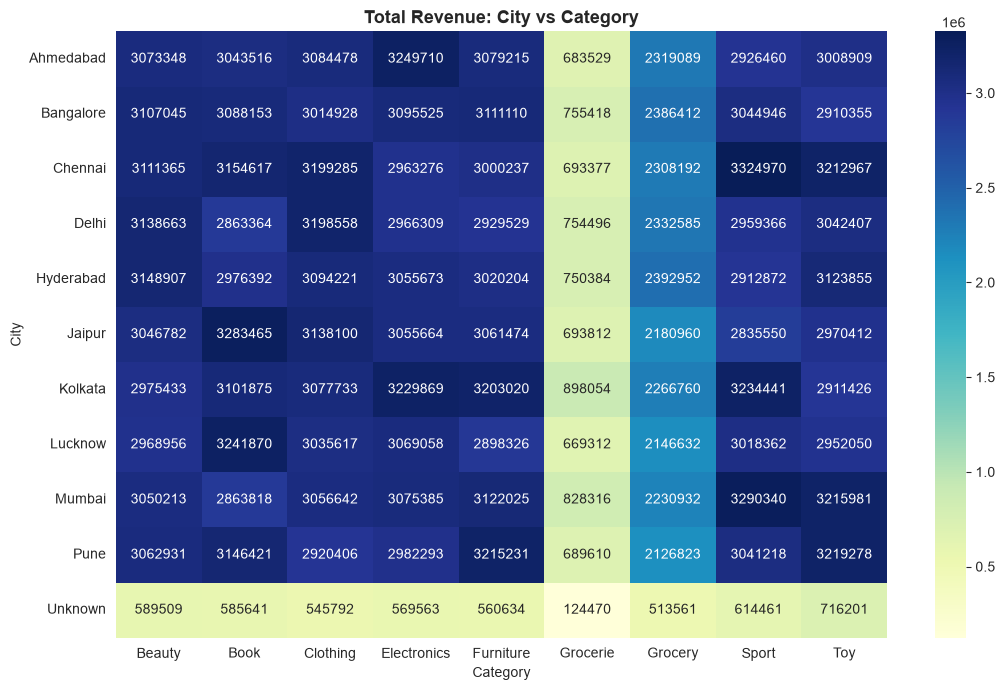

In [4]:
# A heatmap lets us see revenue for every (city, category) combination at once,
# with color intensity making high/low revenue combinations easy to spot
pivot = pd.pivot_table(df, values='final_price', index='city', columns='category',
                        aggfunc='sum', fill_value=0)

plt.figure(figsize=(11, 7))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('Total Revenue: City vs Category')
plt.xlabel('Category')
plt.ylabel('City')
plt.tight_layout()
plt.show()

### 4.2 Category x Payment Mode → Revenue — Grouped Bar Chart

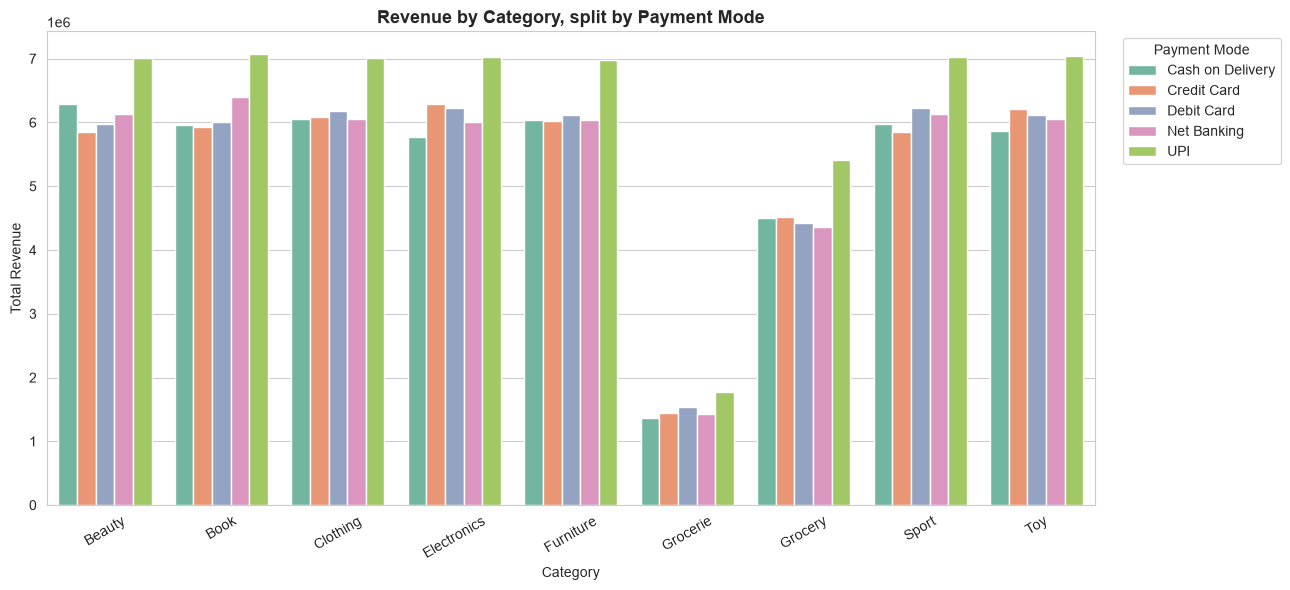

In [5]:
# This shows, for each category, how revenue is split across different payment modes
cat_payment_revenue = df.groupby(['category', 'payment_mode'])['final_price'].sum().reset_index()

plt.figure(figsize=(13, 6))
sns.barplot(data=cat_payment_revenue, x='category', y='final_price', hue='payment_mode', palette='Set2')
plt.title('Revenue by Category, split by Payment Mode')
plt.xlabel('Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=30)
plt.legend(title='Payment Mode', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 4.4 Monthly Revenue Trend, split by Category — Multi-line Chart

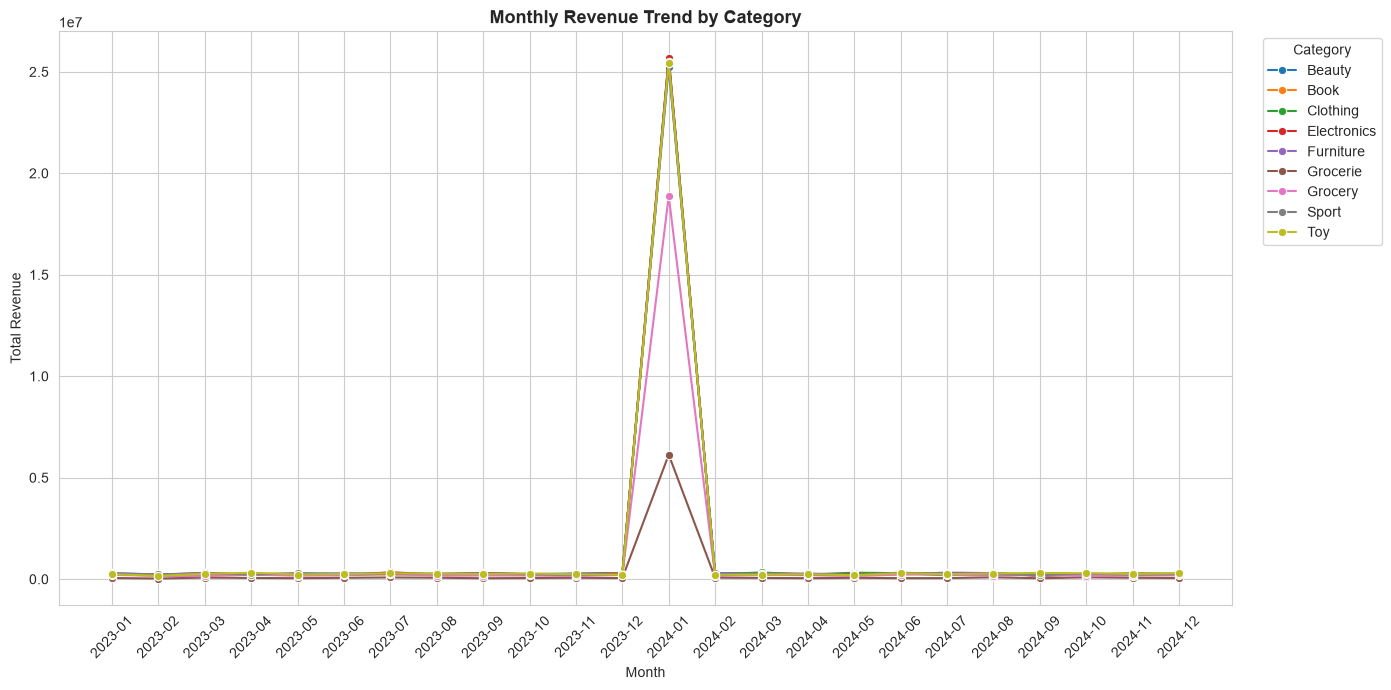

In [6]:
# Comparing revenue trends of every category over time, on the same chart
monthly_cat_revenue = df.groupby(['order_year', 'order_month', 'category'])['final_price'].sum().reset_index()


monthly_cat_revenue['period'] = (monthly_cat_revenue['order_year'].astype(str) + '-' +
                                  monthly_cat_revenue['order_month'].astype(str).str.zfill(2))

monthly_cat_revenue = monthly_cat_revenue.sort_values('period')

plt.figure(figsize=(14, 7))
sns.lineplot(data=monthly_cat_revenue, x='period', y='final_price', hue='category', marker='o')
plt.title('Monthly Revenue Trend by Category')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.legend(title='Category', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 4.5 Correlation Between Numeric Columns — Heatmap

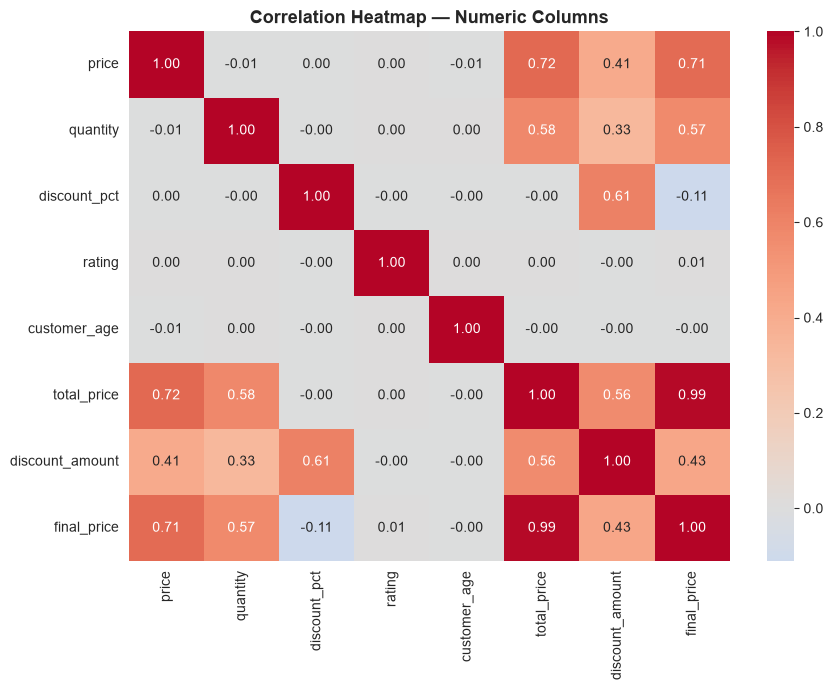

In [7]:
numeric_cols = ['price', 'quantity', 'discount_pct', 'rating', 'customer_age',
                 'total_price', 'discount_amount', 'final_price']

corr_matrix = df[numeric_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap — Numeric Columns')
plt.tight_layout()
plt.show()

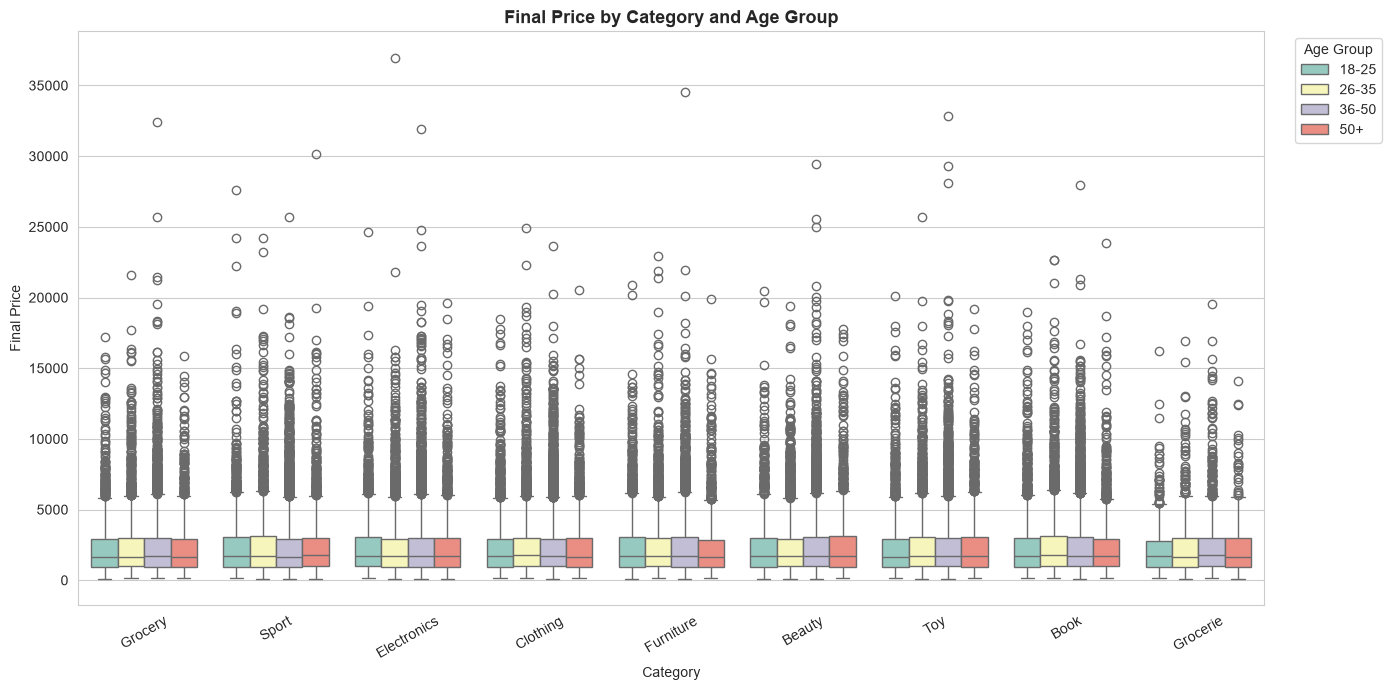

In [8]:
# Combining category + age_group + final_price in one boxplot shows how
# spending patterns differ across both category and customer age simultaneously
plt.figure(figsize=(14, 7))
sns.boxplot(data=df, x='category', y='final_price', hue='age_group', palette='Set3')
plt.title('Final Price by Category and Age Group')
plt.xlabel('Category')
plt.ylabel('Final Price')
plt.xticks(rotation=30)
plt.legend(title='Age Group', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

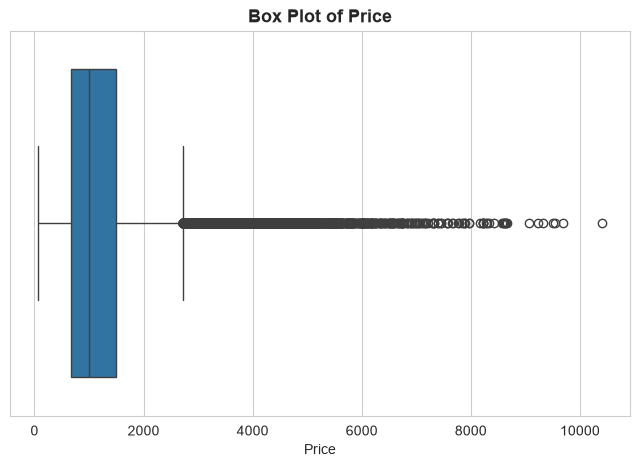

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df['price'])

plt.title('Box Plot of Price')
plt.xlabel('Price')

plt.show()

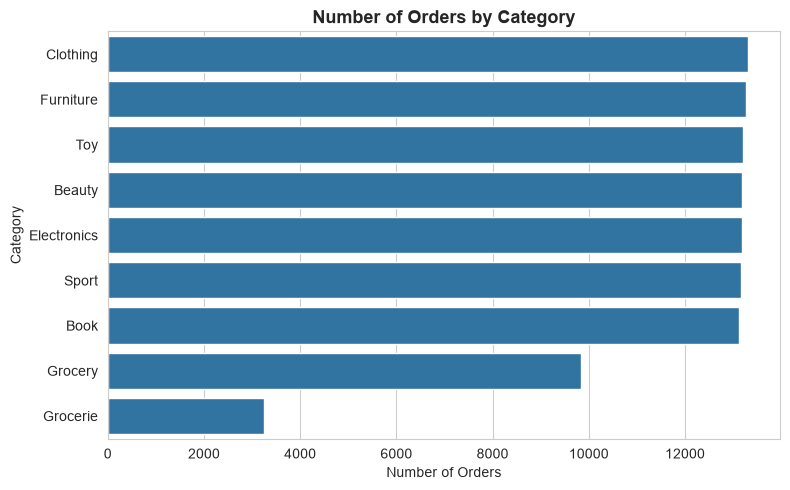

In [10]:
category_counts = df['category'].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title('Number of Orders by Category')
plt.xlabel('Number of Orders')
plt.ylabel('Category')

plt.tight_layout()
plt.show()

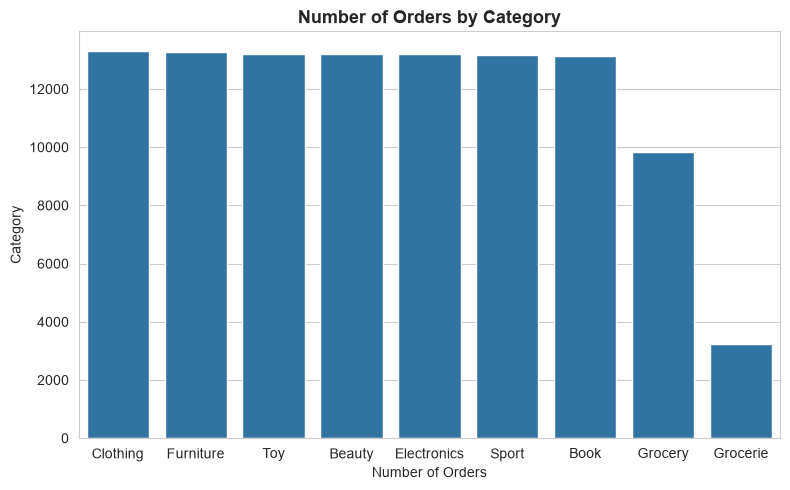

In [11]:
category_counts = df['category'].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_counts.index,
    y=category_counts.values
)

plt.title('Number of Orders by Category')
plt.xlabel('Number of Orders')
plt.ylabel('Category')

plt.tight_layout()
plt.show()

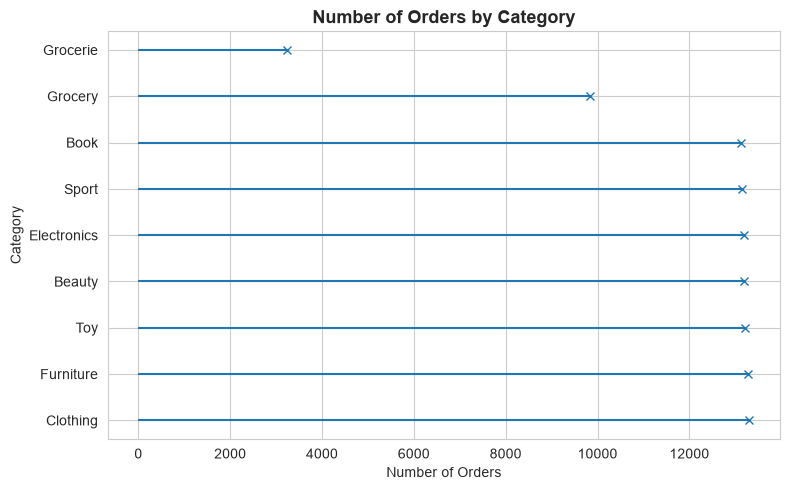

In [12]:
category_counts = df['category'].value_counts()

plt.figure(figsize=(8, 5))

plt.hlines(
    y=category_counts.index,
    xmin=0,
    xmax=category_counts.values
)

plt.plot(
    category_counts.values,
    category_counts.index,
    'x'
)

plt.title('Number of Orders by Category')
plt.xlabel('Number of Orders')
plt.ylabel('Category')

plt.tight_layout()
plt.show()

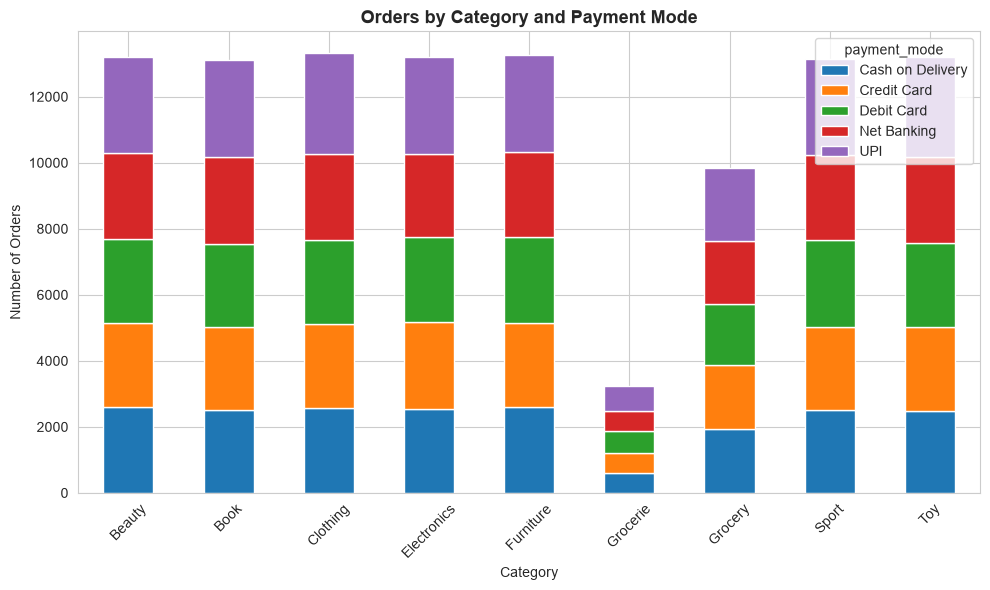

In [13]:
data = pd.crosstab(
    df['category'],
    df['payment_mode']
)

data.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Orders by Category and Payment Mode')
plt.xlabel('Category')
plt.ylabel('Number of Orders')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()